# 03: Call celltypes via `CAS` to we can compare to NanoString annotation
env: `~/miniconda/envs/cpmeasure_icml_cas`

```
pip install \
    pandas \
    anndata \
    matplotlib \
    "scanpy>=1.8" \
    harmonypy \
    mygene \
    cellarium-cas

```

`cellarium-cas` pins a super old version of `AnnData` so we're doing this step without `SpatialData`

tutorial: https://colab.research.google.com/drive/1m9zgqP5n7E4pGGCg5RjfvlCnS6uqUdSa#scrollTo=jsU-CeHyIYhU

In [1]:
import anndata as ad
import pandas as pd
from pathlib import Path
import anndata as ad
import matplotlib.pyplot as plt
import scanpy as sc
import scanpy.external as sce
import json

# for CAS
from cellarium.cas.client import CASClient
from cellarium.cas.postprocessing import insert_cas_ontology_aware_response_into_adata
from cellarium.cas._io import suppress_stderr
import cellarium.cas.postprocessing.ontology_aware as pp
from cellarium.cas.postprocessing.cell_ontology import CellOntologyCache



* [19:30:51.248] Loading cell ontology OWL from: https://github.com/obophenotype/cell-ontology/releases/download/v2024-01-04/cl.owl
* Owlready2 * Warning: ignoring cyclic subclass of/subproperty of, involving:
  http://purl.obolibrary.org/obo/CHEBI_36080
  http://purl.obolibrary.org/obo/PR_000000001

* [19:30:59.062] 
Visualization dependencies not installed.
To install the Cellarium CAS Client with visualation dependencies, please run:
pip install --force-reinstall cellarium-cas[vis]



In [2]:
# safely load cellarium API key

api_key_path = "./cellarium_api_key.json"

with open(api_key_path, "r") as f:
    credentials = json.load(f)

api_token = credentials.get("key")

cas = CASClient(api_token=api_token)
cas_model_name = None # default model

* [19:30:59.078] Connecting to the Cellarium Cloud backend with session 9c8dc17b-af6a-474a-b6e1-8265a2237012...


* [19:31:00.440] User is tim.treis@helmholtz-munich.de
* [19:31:00.652] Client version 1.7.1 is compatible with selected server.
* [19:31:03.380] Authenticated in Cellarium Cloud v. 1.7.3
* [19:31:03.380] Allowed model list in Cellarium CAS:
  - cellarium-pca-v1.1beta (default)
    Description: This model embeds gene expression into a 64-dimensional latent space using PCA, trained on 37,379,002 primary human cells from the CZI CELLxGENE Census (2024-05-06). Preprocessing includes library size normalization, log1p, z-scoring, and selection of the top 10,000 highly variable genes. The vector search index, built from the same dataset with additional QC filters, uses cosine similarity for matching.
    Schema: refdata-gex-GRCh38-2020-A
    Embedding dimension: 64

* [19:31:04.027] Remaining weekly quota: 4772302/5000000
* [19:31:04.027] Weekly quota reset date: 2025-05-18T00:00:00
* [19:31:04.027] Remaining lifetime quota: 99357137/100000000


In [3]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

## Load and pre-process AnnData of gexp

In [86]:
adata_both = ad.read_h5ad(data_dir / "adata_for_cas.h5ad")

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml_cas/lib/python3.11/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [87]:
sc.pp.filter_cells(adata_both, min_genes=50) # only cells with at least 50 genes expressed
sc.pp.filter_genes(adata_both, min_cells=3) # only genes expressed in at least 3 cells

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml_cas/lib/python3.11/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml_cas/lib/python3.11/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [6]:
adata_both.layers["counts"] = adata_both.X.copy()
# sc.pp.normalize_total(adata_both)
# sc.pp.log1p(adata_both)

In [7]:
sc.pp.highly_variable_genes(adata_both, flavor="seurat", batch_key="tissue")
adata_both_hvgs = adata_both[:, adata_both.var["highly_variable"]].copy()
adata_both_hvgs

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml_cas/lib/python3.11/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 86349 × 182
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px', 'n_genes'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg'
    obsm: 'spatial'
    layers: 'counts'

In [8]:
sc.tl.pca(adata_both_hvgs)
sce.pp.harmony_integrate(adata_both_hvgs, key="tissue")

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml_cas/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:249: UserWarning: When using a mask parameter with anndata<0.9 on a dense array, the PCAcan have slightly different results due the array being column major instead of row major.
  warnings.warn(


2025-05-16 19:31:19,606 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-05-16 19:31:30,196 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-05-16 19:31:30,635 - harmonypy - INFO - Iteration 1 of 10
2025-05-16 19:32:12,154 - harmonypy - INFO - Iteration 2 of 10
2025-05-16 19:32:53,267 - harmonypy - INFO - Iteration 3 of 10
2025-05-16 19:33:28,590 - harmonypy - INFO - Iteration 4 of 10
2025-05-16 19:33:41,179 - harmonypy - INFO - Iteration 5 of 10
2025-05-16 19:34:20,831 - harmonypy - INFO - Iteration 6 of 10
2025-05-16 19:34:33,135 - harmonypy - INFO - Iteration 7 of 10
2025-05-16 19:34:45,280 - harmonypy - INFO - Iteration 8 of 10
2025-05-16 19:34:57,184 - harmonypy - INFO - Iteration 9 of 10
2025-05-16 19:35:09,447 - harmonypy - INFO - Iteration 10 of 10
2025-05-16 19:35:21,011 - harmonypy - INFO - Converged after 10 iterations


In [9]:
sc.pp.neighbors(adata_both_hvgs, use_rep="X_pca_harmony")
sc.tl.umap(adata_both_hvgs)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml_cas/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


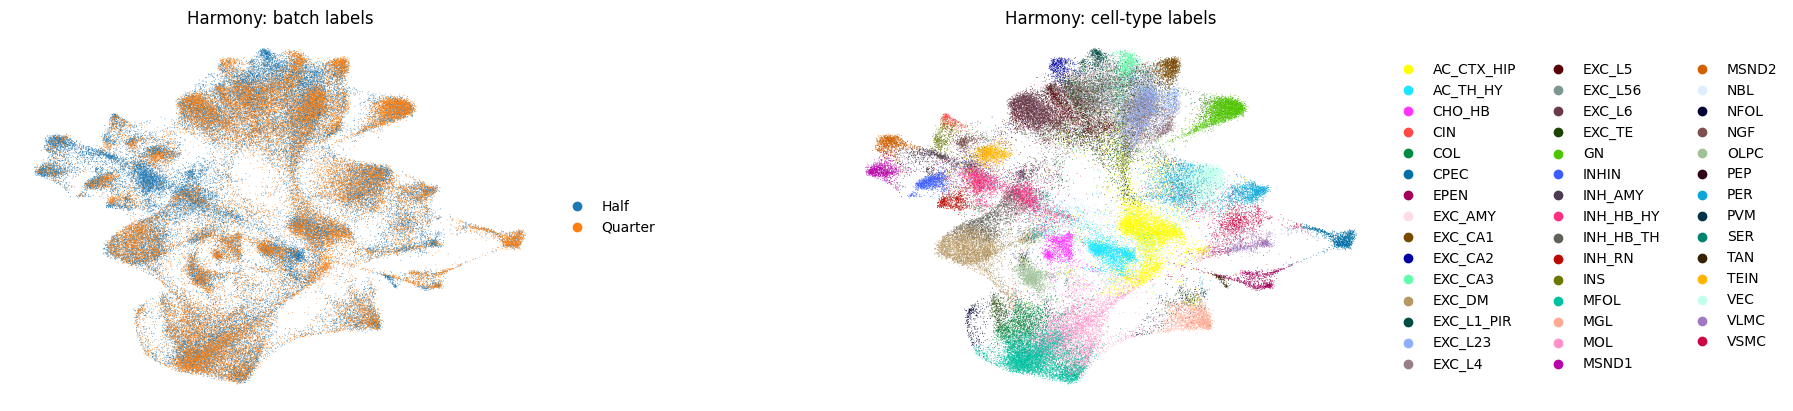

In [10]:
sc.pl.umap(
    adata_both_hvgs,
    color=["tissue", "cluster"],
    wspace=0.4,
    title=["Harmony: batch labels", "Harmony: cell-type labels"],
    frameon=False,
)

We can see mixing for most celltypes while some seem to only exist in the half-brain (like `INH_HB_HY`). Might be expected since the half-brain has a larger section of the tissue.

## CAS annotation

In [11]:
adata_both_hvgs.var

,n_cells,highly_variable,means,dispersions,dispersions_norm,highly_variable_nbatches,highly_variable_intersection
Slc6a1,41900,True,1.020752,1.856755,0.792549,2,True
Aldoc,65006,True,1.938864,2.663151,0.855908,2,True
Id1,22134,True,0.504554,1.791230,1.288503,2,True
Adrb2,11617,True,0.166460,1.161016,0.548419,1,False
Col3a1,8503,True,0.121758,1.250173,0.829482,2,True
...,...,...,...,...,...,...,...
Nos1,18337,True,0.270645,1.320388,0.628898,2,True
Cck,46699,True,1.501179,2.078684,0.691970,1,False
Aqp4,24567,True,0.547897,1.783615,1.269723,2,True
NegPrb6,3579,True,0.048920,1.322194,1.075915,2,True


We're lacking ENSEMBL IDs, let's convert

In [12]:
import mygene

mg = mygene.MyGeneInfo()
gene_symbols = adata_both_hvgs.var_names.tolist()

# Query MyGene to convert symbols to Ensembl IDs
query_result = mg.querymany(gene_symbols, scopes="symbol", fields="ensembl.gene", species="mouse", as_dataframe=True)

# Extract Ensembl IDs (handling duplicates or missing data)
ensembl_ids = query_result["ensembl.gene"]

# Some results may be lists (multiple mappings), handle by choosing first match
def extract_first_id(x):
    if isinstance(x, list):
        return x[0]
    return x

ensembl_ids_cleaned = ensembl_ids.map(extract_first_id)

Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
3 input query terms found no hit:	['Lyz1/2', 'NegPrb6', 'NegPrb9']


In [13]:
ensembl_ids_cleaned

query
Slc6a1     ENSMUSG00000030310
Aldoc      ENSMUSG00000017390
Id1        ENSMUSG00000042745
Adrb2      ENSMUSG00000045730
Col3a1     ENSMUSG00000026043
                  ...        
Nos1       ENSMUSG00000029361
Cck        ENSMUSG00000032532
Aqp4       ENSMUSG00000024411
NegPrb6                   NaN
NegPrb9                   NaN
Name: ensembl.gene, Length: 182, dtype: object

In [14]:
adata_both_hvgs.var["ENSEMBL"] = ensembl_ids_cleaned.values.tolist()

In [15]:
# hack because CAS expectes a sparse matrix
import scipy.sparse as sp

if not sp.issparse(adata_both_hvgs.X):
    adata_both_hvgs.X = sp.csc_matrix(adata_both_hvgs.X)

In [23]:
cas_ontology_aware_response = cas.annotate_matrix_cell_type_ontology_aware_strategy(
    matrix=adata_both_hvgs,
    chunk_size=2000,
    feature_ids_column_name="ENSEMBL",
    feature_names_column_name="index",
    cas_model_name=cas_model_name
)

* [19:53:32.971] Cellarium CAS (Model ID: cellarium-pca-v1.1beta)
* [19:53:32.971] Total number of input cells: 86349


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml_cas/lib/python3.11/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


* [19:53:36.059] The input data matrix has 180 extra features compared to 'refdata-gex-GRCh38-2020-A' CAS schema (36601). Extra input features will be dropped.
* [19:53:36.059] The input data matrix has 36601 missing features compared to 'refdata-gex-GRCh38-2020-A' CAS schema (36601). Missing features will be imputed with zeros.


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml_cas/lib/python3.11/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


* [19:53:36.657] Submitting cell chunk # 1 (    0,  2000) to CAS ...
* [19:53:40.048] Submitting cell chunk # 2 ( 2000,  4000) to CAS ...
* [19:53:40.159] Submitting cell chunk # 3 ( 4000,  6000) to CAS ...
* [19:53:40.268] Submitting cell chunk # 4 ( 6000,  8000) to CAS ...
* [19:53:40.381] Submitting cell chunk # 5 ( 8000, 10000) to CAS ...
* [19:53:40.492] Submitting cell chunk # 6 (10000, 12000) to CAS ...
* [19:53:40.603] Submitting cell chunk # 7 (12000, 14000) to CAS ...
* [19:53:40.713] Submitting cell chunk # 8 (14000, 16000) to CAS ...
* [19:53:40.824] Submitting cell chunk # 9 (16000, 18000) to CAS ...
* [19:53:40.934] Submitting cell chunk #10 (18000, 20000) to CAS ...
* [19:53:41.045] Submitting cell chunk #11 (20000, 22000) to CAS ...
* [19:53:41.156] Submitting cell chunk #12 (22000, 24000) to CAS ...
* [19:53:41.271] Submitting cell chunk #13 (24000, 26000) to CAS ...
* [19:53:41.379] Submitting cell chunk #14 (26000, 28000) to CAS ...
* [19:53:41.488] Submitting cell c

In [17]:
with suppress_stderr():
    cl = CellOntologyCache()

insert_cas_ontology_aware_response_into_adata(cas_ontology_aware_response, adata_both_hvgs)

* [19:50:42.654] Loading cell ontology OWL from: https://github.com/obophenotype/cell-ontology/releases/download/v2024-01-04/cl.owl


In [24]:
pp.compute_most_granular_top_k_calls_single(
    adata=adata_both_hvgs,
    cl=cl,
    min_acceptable_score=0.7,  # minimum acceptable evidence score for a cell type call
    top_k=3,  
    obs_prefix="cas_cell_type"  # .obs column to write the top-k calls to
)

In [27]:
adata_both_hvgs.obs["cas_cell_type_label_1"]

0        hematopoietic cell
1        hematopoietic cell
2        hematopoietic cell
3        hematopoietic cell
4        hematopoietic cell
                ...        
38989    hematopoietic cell
38990    hematopoietic cell
38991    hematopoietic cell
38993    hematopoietic cell
38994    hematopoietic cell
Name: cas_cell_type_label_1, Length: 86349, dtype: object

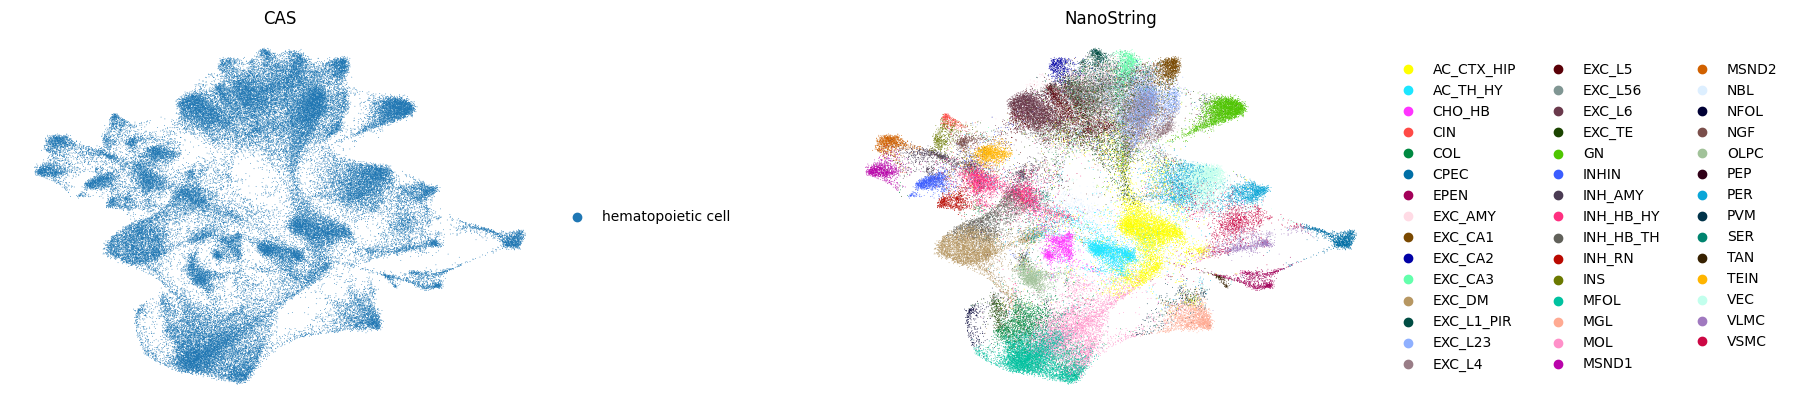

In [32]:
sc.pl.umap(
    adata_both_hvgs,
    color=["cas_cell_type_label_1", "cluster"],
    wspace=0.4,
    title=["CAS", "NanoString"],
    frameon=False,
)

In [88]:
gene_symbols = adata_both.var_names.tolist()
query_result = mg.querymany(gene_symbols, scopes="symbol", fields="ensembl.gene", species="mouse", as_dataframe=True)
query_result = query_result.loc[~query_result.index.duplicated(keep="first")]
ensembl_ids = query_result["ensembl.gene"]
ensembl_ids_cleaned = ensembl_ids.map(extract_first_id)

adata_both.var["ENSEMBL"] = ensembl_ids_cleaned.values.tolist()

Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
1 input query terms found dup hits:	[('Nrg1', 2)]
18 input query terms found no hit:	['Aph1b/c', 'Bex1/2', 'C1s1/2', 'Atpif1', 'Lyz1/2', 'Lilrb4a/b', 'Tuba1a/b/c', 'Gba', 'NegPrb1', 'Ne


In [89]:
# hack because CAS expectes a sparse matrix

# adata_both.X = adata_both.layers["counts"]

if not sp.issparse(adata_both.X):
    adata_both.X = sp.csc_matrix(adata_both.X)

In [90]:
cas_ontology_aware_response = cas.annotate_matrix_cell_type_ontology_aware_strategy(
    matrix=adata_both,
    chunk_size=1500,
    feature_ids_column_name="ENSEMBL",
    feature_names_column_name="index",
    cas_model_name=cas_model_name
)

* [22:13:11.340] Cellarium CAS (Model ID: cellarium-pca-v1.1beta)
* [22:13:11.341] Total number of input cells: 86349


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml_cas/lib/python3.11/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


* [22:13:12.599] The input data matrix has 943 extra features compared to 'refdata-gex-GRCh38-2020-A' CAS schema (36601). Extra input features will be dropped.
* [22:13:12.600] The input data matrix has 36601 missing features compared to 'refdata-gex-GRCh38-2020-A' CAS schema (36601). Missing features will be imputed with zeros.
* [22:13:12.650] Submitting cell chunk # 1 (    0,  2000) to CAS ...


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml_cas/lib/python3.11/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


* [22:13:13.132] Submitting cell chunk # 2 ( 2000,  4000) to CAS ...
* [22:13:13.193] Submitting cell chunk # 3 ( 4000,  6000) to CAS ...
* [22:13:13.253] Submitting cell chunk # 4 ( 6000,  8000) to CAS ...
* [22:13:13.312] Submitting cell chunk # 5 ( 8000, 10000) to CAS ...
* [22:13:13.374] Submitting cell chunk # 6 (10000, 12000) to CAS ...
* [22:13:13.437] Submitting cell chunk # 7 (12000, 14000) to CAS ...
* [22:13:13.499] Submitting cell chunk # 8 (14000, 16000) to CAS ...
* [22:13:13.560] Submitting cell chunk # 9 (16000, 18000) to CAS ...
* [22:13:13.621] Submitting cell chunk #10 (18000, 20000) to CAS ...
* [22:13:13.680] Submitting cell chunk #11 (20000, 22000) to CAS ...
* [22:13:13.741] Submitting cell chunk #12 (22000, 24000) to CAS ...
* [22:13:13.801] Submitting cell chunk #13 (24000, 26000) to CAS ...
* [22:13:13.861] Submitting cell chunk #14 (26000, 28000) to CAS ...
* [22:13:13.923] Submitting cell chunk #15 (28000, 30000) to CAS ...
* [22:13:13.987] Submitting cell c

In [91]:
with suppress_stderr():
    cl = CellOntologyCache()

insert_cas_ontology_aware_response_into_adata(cas_ontology_aware_response, adata_both)

* [22:20:19.682] Loading cell ontology OWL from: https://github.com/obophenotype/cell-ontology/releases/download/v2024-01-04/cl.owl


In [70]:
adata_both.X = adata_both.layers["counts"]

In [92]:
pp.compute_most_granular_top_k_calls_single(
    adata=adata_both,
    cl=cl,
    min_acceptable_score=0.7,  # minimum acceptable evidence score for a cell type call
    top_k=3,  
    obs_prefix="cas_cell_type"  # .obs column to write the top-k calls to
)

In [95]:
adata_both.obs["cas_cell_type_label_1"]

0        hematopoietic cell
1        hematopoietic cell
2        hematopoietic cell
3        hematopoietic cell
4        hematopoietic cell
                ...        
38989    hematopoietic cell
38990    hematopoietic cell
38991    hematopoietic cell
38993    hematopoietic cell
38994    hematopoietic cell
Name: cas_cell_type_label_1, Length: 86349, dtype: object

In [79]:
adata_both.X.todense().sum(axis=1)

matrix([[216],
        [325],
        [508],
        ...,
        [759],
        [120],
        [152]])